Device: cuda
GPU   : Tesla T4
Dataset: /kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge/FloodNet Challenge - Track 1
Building 400×300 resize cache (one-time) ...
Split: train 199 (26 flooded) | valid 199 (25 flooded)

Dense resnet18: 11.18M params | 8.94 GFLOPs @ 400×300
Training dense resnet18 | 50 epochs | SGD lr=0.01 ...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s] 


    dense ep  1/50 │ loss  0.7112 │ acc 0.9347 │ f1 0.7636 │ auc 0.9520
    dense ep  2/50 │ loss  0.5435 │ acc 0.9598 │ f1 0.8182 │ auc 0.9632
    dense ep  3/50 │ loss  0.4148 │ acc 0.9598 │ f1 0.8400 │ auc 0.9600
    dense ep  4/50 │ loss  0.3336 │ acc 0.6332 │ f1 0.3967 │ auc 0.9526
    dense ep  5/50 │ loss  0.3569 │ acc 0.9347 │ f1 0.7719 │ auc 0.9598
    dense ep  6/50 │ loss  0.2144 │ acc 0.8593 │ f1 0.6216 │ auc 0.9568
    dense ep  7/50 │ loss  0.2253 │ acc 0.9347 │ f1 0.7719 │ auc 0.9586
    dense ep  8/50 │ loss  0.2157 │ acc 0.5427 │ f1 0.3453 │ auc 0.9586
    dense ep  9/50 │ loss  0.2306 │ acc 0.9296 │ f1 0.7586 │ auc 0.9648
    dense ep 10/50 │ loss  0.1489 │ acc 0.9749 │ f1 0.8936 │ auc 0.9651
    dense ep 11/50 │ loss  0.1902 │ acc 0.9698 │ f1 0.8696 │ auc 0.9722
    dense ep 12/50 │ loss  0.1054 │ acc 0.9698 │ f1 0.8696 │ auc 0.9761
    dense ep 13/50 │ loss  0.1334 │ acc 0.9698 │ f1 0.8696 │ auc 0.9777
    dense ep 14/50 │ loss  0.1108 │ acc 0.9397 │ f1 0.7857 │ auc

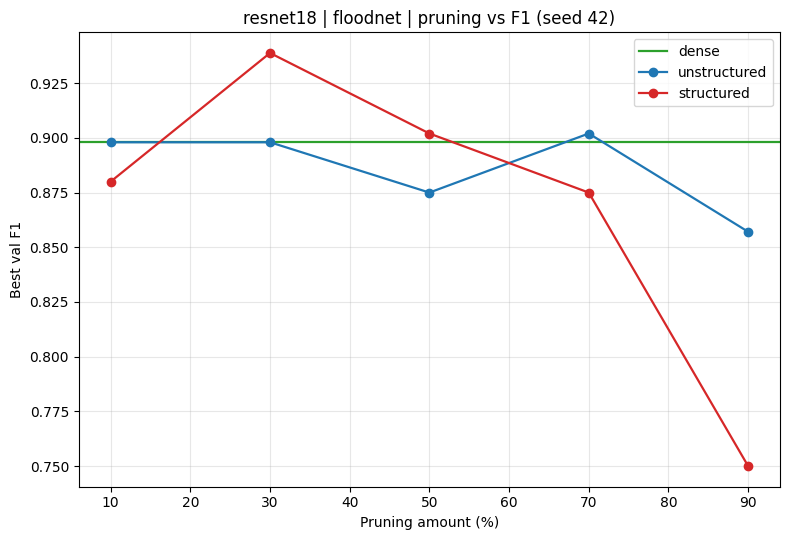

Saved → resnet18_floodnet_prune_plot.png

✓ All done.


In [1]:

import os, copy, glob, random, time, warnings
warnings.filterwarnings("ignore")
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune
import torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
)
import matplotlib.pyplot as plt

# ── 0. Knobs (IDENTICAL across both datasets — lead's requirement) ─────
MODEL_NAME = "resnet18"
DATASET    = "floodnet"
SEED       = 42                                  # training + split seed
LEVELS     = [0.10, 0.30, 0.50, 0.70, 0.90]      # lead's 5 ratios
METHODS    = ["unstructured", "structured"]      # trim if only one needed
E          = 50                                  # dense epochs
FT_EPOCHS  = 50                                  # fine-tune epochs
LR         = 0.01                                # SGD, no momentum
BATCH      = 64 if MODEL_NAME == "resnet18" else 16
IMG_W, IMG_H = 400, 300

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
TAG = f"{MODEL_NAME}_{DATASET}"
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda": print(f"GPU   : {torch.cuda.get_device_name(0)}")

# ── 1. Locate FloodNet Track-1 ─────────────────────────────────────────
CANDIDATE_ROOTS = [
    "/kaggle/input/datasets/aletbm/aerial-imagery-dataset-floodnet-challenge",
    "/kaggle/input/aerial-imagery-dataset-floodnet-challenge",
    "/kaggle/input",
]
BASE = None
for root in CANDIDATE_ROOTS:
    if not os.path.isdir(root): continue
    for dirpath, dirnames, _ in os.walk(root):
        if "Labeled" in dirnames and Path(dirpath).name == "Train":
            BASE = str(Path(dirpath).parent); break
    if BASE: break
if BASE is None:
    import kagglehub
    dl = kagglehub.dataset_download(
        "aletbm/aerial-imagery-dataset-floodnet-challenge")
    for dirpath, dirnames, _ in os.walk(dl):
        if "Labeled" in dirnames and Path(dirpath).name == "Train":
            BASE = str(Path(dirpath).parent); break
assert BASE is not None, "Could not locate the FloodNet Track-1 folder."
print(f"Dataset: {BASE}")

def get_images(folder):
    return sorted(glob.glob(os.path.join(folder, "*.jpg"))  +
                  glob.glob(os.path.join(folder, "*.png"))  +
                  glob.glob(os.path.join(folder, "*.jpeg")))

FLOODED_DIR    = os.path.join(BASE, "Train", "Labeled", "Flooded",     "image")
NONFLOODED_DIR = os.path.join(BASE, "Train", "Labeled", "Non-Flooded", "image")

# ── 2. One-time 400×300 resize cache (labeled images only) ─────────────
CACHE = os.path.join(OUT, "floodnet_resized_400x300")

def cached_path(src):
    return os.path.join(CACHE, os.path.relpath(src, BASE))

def build_cache(paths):
    for p in paths:
        dst = cached_path(p)
        if os.path.exists(dst): continue
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        cv2.imwrite(dst, cv2.resize(cv2.imread(p), (IMG_W, IMG_H)))

flooded_files    = get_images(FLOODED_DIR)
nonflooded_files = get_images(NONFLOODED_DIR)
print("Building 400×300 resize cache (one-time) ...")
build_cache(flooded_files); build_cache(nonflooded_files)
flooded_files    = [cached_path(p) for p in flooded_files]
nonflooded_files = [cached_path(p) for p in nonflooded_files]

# ── 3. 50/50 stratified split (same as ResNet18 replication) ───────────
X = flooded_files + nonflooded_files
y = [1]*len(flooded_files) + [0]*len(nonflooded_files)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.5, stratify=y, random_state=SEED)
print(f"Split: train {len(X_train)} ({sum(y_train)} flooded) | "
      f"valid {len(X_valid)} ({sum(y_valid)} flooded)")
assert sum(y_valid) > 0 and sum(y_valid) < len(y_valid), \
    "Validation set must contain BOTH classes."

# ── 4. Datasets / loaders ──────────────────────────────────────────────
tfm_train = T.Compose([
    T.ToPILImage(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
tfm_valid = T.Compose([
    T.ToPILImage(), T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class ImgDataset(Dataset):
    def __init__(self, X, y, transform):
        self.X, self.y, self.transform = X, y, transform
    def __len__(self): return len(self.X)
    def __getitem__(self, idx):
        img = cv2.cvtColor(cv2.imread(self.X[idx]), cv2.COLOR_BGR2RGB)
        return self.transform(img), self.y[idx]

_, counts      = np.unique(y_train, return_counts=True)
class_weights  = [1.0/c for c in counts]
sample_weights = [class_weights[l] for l in y_train]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights),
                                replacement=True)

train_ldr = DataLoader(ImgDataset(X_train, y_train, tfm_train),
                       batch_size=BATCH, sampler=sampler,
                       num_workers=2, pin_memory=True)
valid_ldr = DataLoader(ImgDataset(X_valid, y_valid, tfm_valid),
                       batch_size=BATCH, shuffle=False,
                       num_workers=2, pin_memory=True)

# ── 5. Model builder ───────────────────────────────────────────────────
def build_model(pretrained=True):
    if MODEL_NAME == "resnet18":
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        m = torchvision.models.resnet18(weights=w)
        m.fc = nn.Linear(m.fc.in_features, 2)
    else:
        w = torchvision.models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None
        m = torchvision.models.vgg16(weights=w)
        m.classifier[-1] = nn.Linear(4096, 2)
    return m

# ── 6. Params & MACs profiler (hook-based) ─────────────────────────────
def profile_model(model):
    model = model.to("cpu").eval()
    macs_total, per_layer, hooks = {"v": 0}, {}, []
    def conv_hook(name):
        def fn(mod, inp, out):
            k = mod.kernel_size[0] * mod.kernel_size[1]
            macs = out.numel() * (mod.in_channels // mod.groups) * k
            macs_total["v"] += macs; per_layer[name] = macs
        return fn
    def lin_hook(name):
        def fn(mod, inp, out):
            macs = mod.in_features * mod.out_features
            macs_total["v"] += macs; per_layer[name] = macs
        return fn
    for name, mod in model.named_modules():
        if isinstance(mod, nn.Conv2d):
            hooks.append(mod.register_forward_hook(conv_hook(name)))
        elif isinstance(mod, nn.Linear):
            hooks.append(mod.register_forward_hook(lin_hook(name)))
    with torch.no_grad():
        model(torch.randn(1, 3, IMG_H, IMG_W))
    for h in hooks: h.remove()
    n_params = sum(p.numel() for p in model.parameters())
    return n_params, macs_total["v"], per_layer

def count_nonzero_params(model):
    total, nonzero = 0, 0
    for p in model.parameters():
        total += p.numel(); nonzero += int((p != 0).sum().item())
    return total, nonzero

def effective_macs(model, per_layer_macs):
    eff, named = 0, dict(model.named_modules())
    for lname, macs in per_layer_macs.items():
        mod = named.get(lname)
        if mod is None: eff += macs; continue
        w = mod.weight.detach()
        eff += macs * float((w != 0).sum().item()) / max(w.numel(), 1)
    return eff

# ── 7. Evaluation ──────────────────────────────────────────────────────
def evaluate(model, loader):
    model.eval()
    probs_all, preds_all, lbls_all = [], [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            out   = model(imgs.to(DEVICE))
            probs = torch.softmax(out, 1)[:, 1].cpu().numpy()
            preds = out.argmax(1).cpu().numpy()
            probs_all.extend(probs); preds_all.extend(preds)
            lbls_all.extend(np.asarray(lbls))
    acc  = accuracy_score(lbls_all, preds_all)
    f1   = f1_score(lbls_all,       preds_all, zero_division=0)
    prec = precision_score(lbls_all, preds_all, zero_division=0)
    rec  = recall_score(lbls_all,   preds_all, zero_division=0)
    try:    roc = roc_auc_score(lbls_all, probs_all)
    except: roc = float("nan")
    return acc, f1, prec, rec, roc

# ── 8. Training loop (keeps best-F1 checkpoint) ────────────────────────
def train_loop(model, epochs, tag=""):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)
    best_f1, best_epoch, best_state, best_metrics = -1, -1, None, None
    for ep in range(epochs):
        model.train()
        total_loss, n_b = 0.0, 0
        for imgs, lbls in train_ldr:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(imgs), lbls)
            loss.backward(); optimizer.step()
            total_loss += loss.item(); n_b += 1
        acc, f1, prec, rec, roc = evaluate(model, valid_ldr)
        print(f"    {tag} ep {ep+1:2d}/{epochs} │ "
              f"loss {total_loss/max(n_b,1):7.4f} │ acc {acc:.4f} │ "
              f"f1 {f1:.4f} │ auc {roc:.4f}")
        if f1 > best_f1:
            best_f1, best_epoch = f1, ep + 1
            best_metrics = (acc, f1, prec, rec, roc)
            best_state   = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return best_metrics, best_epoch

# ── 9. Pruning utilities ───────────────────────────────────────────────
def prunable_modules(model):
    return [(n, m) for n, m in model.named_modules()
            if isinstance(m, (nn.Conv2d, nn.Linear))]

def apply_unstructured(model, amount):
    params = [(m, "weight") for _, m in prunable_modules(model)]
    prune.global_unstructured(params, pruning_method=prune.L1Unstructured,
                              amount=amount)

def apply_structured(model, amount):
    """L1 structured: conv output filters + wide FC neurons.
    Final 2-node classifier layer is left intact (out_features ≤ 8)."""
    for _, mod in prunable_modules(model):
        if isinstance(mod, nn.Conv2d) and mod.out_channels > 8:
            prune.ln_structured(mod, "weight", amount=amount, n=1, dim=0)
        elif isinstance(mod, nn.Linear) and mod.out_features > 8:
            prune.ln_structured(mod, "weight", amount=amount, n=1, dim=0)

def finalize_pruning(model):
    for _, mod in prunable_modules(model):
        if prune.is_pruned(mod):
            try: prune.remove(mod, "weight")
            except ValueError: pass

# ── 10. Dense baseline (train or reuse checkpoint) ─────────────────────
def find_weights(fname):
    for base in ["/kaggle/input", "."]:
        if not os.path.isdir(base): continue
        for dirpath, _, filenames in os.walk(base):
            if fname in filenames:
                return os.path.join(dirpath, fname)
    return None

_ref = build_model(pretrained=False)
DENSE_PARAMS, DENSE_MACS, PER_LAYER_MACS = profile_model(_ref)
del _ref
print(f"\nDense {MODEL_NAME}: {DENSE_PARAMS/1e6:.2f}M params | "
      f"{2*DENSE_MACS/1e9:.2f} GFLOPs @ {IMG_W}×{IMG_H}")

fname = f"{TAG}_dense_seed{SEED}.pth"
path  = find_weights(fname)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

if path is not None:
    print(f"Reusing dense checkpoint ← {path}")
    dense_model = build_model(pretrained=False).to(DEVICE)
    dense_model.load_state_dict(torch.load(path, map_location=DEVICE))
    dmetrics, dep = evaluate(dense_model, valid_ldr), -1
else:
    print(f"Training dense {MODEL_NAME} | {E} epochs | SGD lr={LR} ...")
    dense_model = build_model(pretrained=True).to(DEVICE)
    dmetrics, dep = train_loop(dense_model, E, tag="dense")
    torch.save(dense_model.state_dict(), os.path.join(OUT, fname))
    print(f"Saved dense checkpoint → {fname}")

study_rows = []
def record(method, amount, best_ep, nonzero, eff, metrics):
    acc, f1, prec, rec, roc = metrics
    study_rows.append(dict(
        model=MODEL_NAME, dataset=DATASET, seed=SEED,
        method=method, amount=amount, best_epoch=best_ep,
        params_nonzero=nonzero, macs_effective=int(eff),
        accuracy=round(acc,4), f1=round(f1,4), precision=round(prec,4),
        recall=round(rec,4), roc_auc=round(roc,4)))

record("dense", 0.0, dep, DENSE_PARAMS, DENSE_MACS, dmetrics)
print(f"\nDENSE │ acc {dmetrics[0]:.4f} │ F1 {dmetrics[1]:.4f} │ "
      f"AUC {dmetrics[4]:.4f}")

dense_state = copy.deepcopy(dense_model.state_dict())
del dense_model
if DEVICE.type == "cuda": torch.cuda.empty_cache()

# ── 11. PRUNING STUDY ──────────────────────────────────────────────────
for method in METHODS:
    for amount in LEVELS:
        print(f"\n── {MODEL_NAME} │ {DATASET} │ {method} @ {amount:.0%} │ "
              f"FT {FT_EPOCHS} ep ──")
        torch.manual_seed(SEED)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

        model = build_model(pretrained=False).to(DEVICE)
        model.load_state_dict(dense_state)
        if method == "unstructured":
            apply_unstructured(model, amount)
        else:
            apply_structured(model, amount)

        ft_metrics, ft_ep = train_loop(model, FT_EPOCHS,
                                       tag=f"{method[:6]}@{amount:.0%}")
        finalize_pruning(model)
        total, nonzero = count_nonzero_params(model)
        eff = effective_macs(model, PER_LAYER_MACS)
        record(method, amount, ft_ep, nonzero, eff, ft_metrics)
        print(f"  → NZ params {nonzero/1e6:.2f}M │ "
              f"eff FLOPs {2*eff/1e9:.2f}G │ F1 {ft_metrics[1]:.4f} "
              f"(best ep {ft_ep})")

        del model
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
        pd.DataFrame(study_rows).to_csv(
            os.path.join(OUT, f"{TAG}_prune_results.csv"), index=False)

# ── 12. Summary ────────────────────────────────────────────────────────
study_df = pd.DataFrame(study_rows)
study_df.to_csv(os.path.join(OUT, f"{TAG}_prune_results.csv"), index=False)
print(f"\nSaved → {TAG}_prune_results.csv")

print("\n" + "═"*96)
print(f"  PRUNING SUMMARY — {MODEL_NAME} | {DATASET.upper()} | seed {SEED}")
print("═"*96)
print(f"{'Method':<13} │ {'Amt':>4} │ {'NZ params':>10} │ {'F1':>7} │ "
      f"{'Acc':>7} │ {'Prec':>7} │ {'Rec':>7} │ {'AUC':>7}")
print("─"*96)
for _, r in study_df.iterrows():
    print(f"{r['method']:<13} │ {r['amount']:>4.0%} │ "
          f"{r['params_nonzero']/1e6:>8.2f} M │ {r['f1']:>7.4f} │ "
          f"{r['accuracy']:>7.4f} │ {r['precision']:>7.4f} │ "
          f"{r['recall']:>7.4f} │ {r['roc_auc']:>7.4f}")
print("═"*96)

d_f1 = study_df[study_df["method"] == "dense"].iloc[0]["f1"]
print("\n  ΔF1 vs dense:")
for _, r in study_df[study_df["method"] != "dense"].iterrows():
    print(f"    {r['method']:<13} @{r['amount']:>4.0%}  "
          f"ΔF1 = {r['f1'] - d_f1:+.4f}")

# ── 13. Plot ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axhline(d_f1, color="tab:green", linewidth=1.6, label="dense")
mcolors = {"unstructured": "tab:blue", "structured": "tab:red"}
for method in METHODS:
    sub = study_df[study_df["method"] == method].sort_values("amount")
    ax.plot([a*100 for a in sub["amount"]], sub["f1"],
            color=mcolors[method], marker="o", linewidth=1.6, label=method)
ax.set_title(f"{MODEL_NAME} | {DATASET} | pruning vs F1 (seed {SEED})")
ax.set_xlabel("Pruning amount (%)"); ax.set_ylabel("Best val F1")
ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, f"{TAG}_prune_plot.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {TAG}_prune_plot.png")
print("\n✓ All done.")
